In [1]:

from pathlib import Path

# Lokasi folder data relatif terhadap notebook
data_dir = Path("BAKO")
rinex_file = data_dir / "/BAKO/bako3000.03o"

# Periksa keberadaan file
print("Lokasi file:", rinex_file.resolve())
print("File ditemukan:", rinex_file.exists())

if rinex_file.exists():
    print("Ukuran file:", rinex_file.stat().st_size, "bytes")
else:
    print("Periksa kembali nama file dan lokasi folder.")


Lokasi file: C:\BAKO\bako3000.03o
File ditemukan: False
Periksa kembali nama file dan lokasi folder.


In [2]:

from pathlib import Path

rinex_file = Path(
    r"C:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily\HALLOWEEN STORM 2003\DOY 300_27 OCT 2003\BAKO\bako3000.03o"
)

print("Lokasi file:", rinex_file)
print("File ditemukan:", rinex_file.exists())

if rinex_file.exists():
    print("Ukuran file:", rinex_file.stat().st_size, "bytes")
else:
    print("File tidak ditemukan. Periksa kembali lokasi dan nama file.")


Lokasi file: C:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily\HALLOWEEN STORM 2003\DOY 300_27 OCT 2003\BAKO\bako3000.03o
File ditemukan: True
Ukuran file: 2103424 bytes


In [3]:

from pathlib import Path

rinex_file = Path(
    r"C:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily\HALLOWEEN STORM 2003\DOY 300_27 OCT 2003\BAKO\bako3000.03o"
)

# Baca bagian header sampai END OF HEADER
header_lines = []

with rinex_file.open("r", encoding="ascii", errors="replace") as f:
    for line in f:
        header_lines.append(line.rstrip("\r\n"))
        if "END OF HEADER" in line:
            break

print("Jumlah baris header:", len(header_lines))
print("\n".join(header_lines))


Jumlah baris header: 18
     2.10           OBSERVATION DATA    G (GPS)             RINEX VERSION / TYPE
teqc  2002Mar14                         20031028 12:06:32UTCPGM / RUN BY / DATE
MSWin2000|IAx86-PII|wcl386 11.0|MSWin95/98/NT/2000|486/DX+  COMMENT
BIT 2 OF LLI FLAGS DATA COLLECTED UNDER A/S CONDITION       COMMENT
bako                                                        MARKER NAME
23101M002                                                   MARKER NUMBER
eka                 bakosurtanal                            OBSERVER / AGENCY
2491                TRIMBLE 4000SSE     NP 7.19 / SP 3.04   REC # / TYPE / VERS
44148               TRM14532.00     NONE                    ANT # / TYPE
 -1836967.8873  6065615.4384  -716260.3127                  APPROX POSITION XYZ
        1.6160        0.0000        0.0000                  ANTENNA: DELTA H/E/N
     1     1                                                WAVELENGTH FACT L1/2
     6    L1    L2    C1    P2    P1    D1                  

In [4]:

from pathlib import Path

rinex_file = Path(
    r"C:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily\HALLOWEEN STORM 2003\DOY 300_27 OCT 2003\BAKO\bako3000.03o"
)

epoch_count = 0

with rinex_file.open("r", encoding="ascii", errors="replace") as f:
    # Lewati header
    for line in f:
        if "END OF HEADER" in line:
            break

    # Tampilkan lima baris epoch pertama
    for line in f:
        if line.startswith(" "):
            print(repr(line.rstrip("\r\n")))
            epoch_count += 1

        if epoch_count == 5:
            break


' 03 10 27  0  0 30.0000000  0  9G21G 6G 5G25G15G18G30G14G23'
'   7272414.07557   5719375.47357  20659955.1484   20659955.7704'
'     -3921.0944'
'  35449963.44555   2632699.29255  23215464.2584   23215469.9774'
'     -3146.2974'


In [5]:
%pip install georinex

   ---------------------------------------- 0.0/21.3 MB ? eta -:--:--
    --------------------------------------- 0.5/21.3 MB 3.1 MB/s eta 0:00:07
   -- ------------------------------------- 1.3/21.3 MB 3.2 MB/s eta 0:00:07
   ---- ----------------------------------- 2.4/21.3 MB 3.9 MB/s eta 0:00:05
   ------ --------------------------------- 3.4/21.3 MB 4.4 MB/s eta 0:00:05
   -------- ------------------------------- 4.7/21.3 MB 4.7 MB/s eta 0:00:04
   --------- ------------------------------ 5.0/21.3 MB 4.4 MB/s eta 0:00:04
   ---------- ----------------------------- 5.5/21.3 MB 3.9 MB/s eta 0:00:05
   ----------- ---------------------------- 6.3/21.3 MB 3.8 MB/s eta 0:00:04
   -------------- ------------------------- 7.6/21.3 MB 4.2 MB/s eta 0:00:04
   ---------------- ----------------------- 8.7/21.3 MB 4.2 MB/s eta 0:00:04
   ----------------- ---------------------- 9.4/21.3 MB 4.2 MB/s eta 0:00:03
   ------------------- -------------------- 10.5/21.3 MB 4.3 MB/s eta 0:00:03
   --


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:

import georinex as gr
from pathlib import Path

rinex_file = Path(
    r"C:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily\HALLOWEEN STORM 2003\DOY 300_27 OCT 2003\BAKO\bako3000.03o"
)

print("Versi GeoRinex:", gr.__version__)
print("File tersedia:", rinex_file.exists())

# Baca metadata header saja, belum memproses seluruh observasi
header = gr.rinexheader(str(rinex_file))

print("\nMetadata yang berhasil dibaca:")
for key, value in header.items():
    print(f"{key}: {value}")


Versi GeoRinex: 1.16.2
File tersedia: True

Metadata yang berhasil dibaca:
version: 2.1
filetype: O
rinextype: obs
systems: G
PGM / RUN BY / DATE: teqc  2002Mar14                         20031028 12:06:32UTC
COMMENT: MSWin2000|IAx86-PII|wcl386 11.0|MSWin95/98/NT/2000|486/DX+   BIT 2 OF LLI FLAGS DATA COLLECTED UNDER A/S CONDITION         SNR is mapped to RINEX snr flag value [1-9]                   L1: 3 -> 1; 8 -> 5; 40 -> 9                                  L2: 1 -> 1; 5 -> 5; 60 -> 9                               
MARKER NAME: bako                                                        
MARKER NUMBER: 23101M002                                                   
OBSERVER / AGENCY: eka                 bakosurtanal                            
REC # / TYPE / VERS: 2491                TRIMBLE 4000SSE     NP 7.19 / SP 3.04   
ANT # / TYPE: 44148               TRM14532.00     NONE                    
APPROX POSITION XYZ:  -1836967.8873  6065615.4384  -716260.3127                  
ANTENNA: 

In [7]:

import georinex as gr

# Baca data observasi RINEX
obs = gr.load(str(rinex_file))

print("Dimensi data:", obs.sizes)
print("\nKoordinat waktu:")
print("Jumlah epoch:", obs.sizes.get("time", 0))
print("Waktu pertama:", obs.time.values[0] if obs.sizes.get("time", 0) else "Tidak ada")
print("Waktu terakhir:", obs.time.values[-1] if obs.sizes.get("time", 0) else "Tidak ada")

print("\nJenis observasi yang terbaca:")
print(list(obs.data_vars))

print("\nRingkasan dataset:")
print(obs)


Dimensi data: Frozen({'time': 2878, 'sv': 28})

Koordinat waktu:
Jumlah epoch: 2878
Waktu pertama: 2003-10-27T00:00:30.000000000
Waktu terakhir: 2003-10-27T23:59:00.128000000

Jenis observasi yang terbaca:
['L1', 'L2', 'C1', 'P2', 'P1', 'D1']

Ringkasan dataset:
<xarray.Dataset> Size: 4MB
Dimensions:  (time: 2878, sv: 28)
Coordinates:
  * time     (time) datetime64[ns] 23kB 2003-10-27T00:00:30 ... 2003-10-27T23...
  * sv       (sv) <U3 336B 'G01' 'G02' 'G03' 'G04' ... 'G28' 'G29' 'G30' 'G31'
Data variables:
    L1       (time, sv) float64 645kB nan nan nan nan ... nan nan 3.487e+07 nan
    L2       (time, sv) float64 645kB nan nan nan nan ... nan nan 1.001e+07 nan
    C1       (time, sv) float64 645kB nan nan nan nan ... nan nan 5.949e+07 nan
    P2       (time, sv) float64 645kB nan nan nan nan ... nan nan 5.949e+07 nan
    P1       (time, sv) float64 645kB nan nan nan nan nan ... nan nan nan nan
    D1       (time, sv) float64 645kB nan nan nan nan ... nan nan -2.228e+03 nan
Attribut

c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))
c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'sv' ('sv',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))


In [8]:

import pandas as pd

# Ambil koordinat waktu dari dataset
times = pd.DatetimeIndex(obs.time.values)

# Hitung selisih waktu antara epoch berurutan
time_diff = times.to_series().diff().dropna()

print("Jumlah epoch:", len(times))
print("\nStatistik selisih waktu antar-epoch (detik):")
print(time_diff.dt.total_seconds().describe())

print("\nFrekuensi selisih waktu yang paling umum (detik):")
print(time_diff.dt.total_seconds().value_counts().head(10))

print("\nSepuluh selisih waktu pertama (detik):")
print(time_diff.dt.total_seconds().head(10).to_list())


Jumlah epoch: 2878

Statistik selisih waktu antar-epoch (detik):
count    2877.000000
mean       30.000044
std         0.000734
min        29.999000
25%        30.000000
50%        30.000000
75%        30.001000
max        30.002000
dtype: float64

Frekuensi selisih waktu yang paling umum (detik):
30.000    1420
30.001     743
29.999     681
30.002      33
Name: count, dtype: int64

Sepuluh selisih waktu pertama (detik):
[30.0, 30.0, 30.001, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0]


In [9]:

# Selisih waktu antar-epoch dalam detik
intervals = time_diff.dt.total_seconds()

# Deteksi kandidat jeda yang lebih panjang dari interval nominal
gap_threshold = 30.5
gap_candidates = intervals[intervals > gap_threshold]

print("Ambang deteksi jeda:", gap_threshold, "detik")
print("Jumlah kandidat jeda:", len(gap_candidates))

if len(gap_candidates) > 0:
    print("\nKandidat jeda:")
    for timestamp, seconds in gap_candidates.items():
        print(
            "Epoch setelah jeda:", timestamp,
            "| Selisih:", seconds, "detik"
        )
else:
    print("Tidak ditemukan selisih antar-epoch > 30,5 detik.")



Ambang deteksi jeda: 30.5 detik
Jumlah kandidat jeda: 0
Tidak ditemukan selisih antar-epoch > 30,5 detik.


In [10]:

# Rentang waktu pengamatan
first_time = times[0]
last_time = times[-1]

# Durasi dari epoch pertama hingga epoch terakhir
observed_duration = (last_time - first_time).total_seconds()

# Interval nominal dari metadata GeoRinex
nominal_interval = float(obs.attrs["interval"])

# Jumlah epoch yang diharapkan dari rentang waktu tersebut,
# jika interval nominal 30 detik teratur
expected_epochs = round(observed_duration / nominal_interval) + 1

print("Epoch pertama       :", first_time)
print("Epoch terakhir      :", last_time)
print("Durasi pengamatan   :", observed_duration, "detik")
print("Durasi pengamatan   :", observed_duration / 3600, "jam")
print("Interval nominal    :", nominal_interval, "detik")
print("Jumlah epoch aktual :", len(times))
print("Jumlah epoch harapan:", expected_epochs)
print("Selisih jumlah      :", len(times) - expected_epochs)


Epoch pertama       : 2003-10-27 00:00:30
Epoch terakhir      : 2003-10-27 23:59:00.128000
Durasi pengamatan   : 86310.128 detik
Durasi pengamatan   : 23.975035555555554 jam
Interval nominal    : 30.0 detik
Jumlah epoch aktual : 2878
Jumlah epoch harapan: 2878
Selisih jumlah      : 0


In [11]:

import pandas as pd

# Hitung jumlah dan persentase nilai kosong setiap jenis observasi
missing_count = obs.to_array().isnull().sum(dim=("time", "sv"))

total_values = obs.sizes["time"] * obs.sizes["sv"]

missing_summary = pd.DataFrame({
    "Jenis observasi": list(obs.data_vars),
    "Jumlah kosong": [
        int(obs[var].isnull().sum().item())
        for var in obs.data_vars
    ],
    "Total sel": [
        int(obs[var].size)
        for var in obs.data_vars
    ],
    "Persentase kosong (%)": [
        float(obs[var].isnull().mean().item() * 100)
        for var in obs.data_vars
    ]
})

print(missing_summary.to_string(index=False))


Jenis observasi  Jumlah kosong  Total sel  Persentase kosong (%)
             L1          56347      80584              69.923310
             L2          56704      80584              70.366326
             C1          56330      80584              69.902214
             P2          56704      80584              70.366326
             P1          80584      80584             100.000000
             D1          56330      80584              69.902214


In [12]:

# Jumlah nilai valid pada setiap jenis observasi
print("JUMLAH OBSERVASI VALID PER JENIS")
for var in obs.data_vars:
    valid = int(obs[var].count().item())
    total = int(obs[var].size)
    print(f"{var}: {valid:,} dari {total:,} sel")

# Jumlah nilai L1 dan L2 yang tersedia per satelit
satellite_summary = pd.DataFrame({
    "L1_valid": obs["L1"].notnull().sum(dim="time").to_series(),
    "L2_valid": obs["L2"].notnull().sum(dim="time").to_series(),
})

satellite_summary.index.name = "Satelit"

print("\nJUMLAH OBSERVASI VALID PER SATELIT")
print(satellite_summary.to_string())

# Ringkasan jumlah satelit yang memiliki L1 pada setiap epoch
satellites_per_epoch = obs["L1"].notnull().sum(dim="sv")

print("\nJUMLAH SATELIT DENGAN L1 VALID PER EPOCH")
print("Minimum:", int(satellites_per_epoch.min().item()))
print("Maksimum:", int(satellites_per_epoch.max().item()))
print("Rata-rata:", round(float(satellites_per_epoch.mean().item()), 2))


JUMLAH OBSERVASI VALID PER JENIS
L1: 24,237 dari 80,584 sel
L2: 23,880 dari 80,584 sel
C1: 24,254 dari 80,584 sel
P2: 23,880 dari 80,584 sel
P1: 0 dari 80,584 sel
D1: 24,254 dari 80,584 sel

JUMLAH OBSERVASI VALID PER SATELIT
         L1_valid  L2_valid
Satelit                    
G01           702       691
G02          1083      1068
G03           726       724
G04          1001       939
G05          1084      1064
G06          1029       998
G07          1173      1161
G08           725       715
G09           836       827
G10           662       660
G11           769       767
G13          1047      1006
G14          1069      1058
G15           814       788
G16           695       693
G17           828       813
G18           691       682
G20          1101      1094
G21           674       672
G23           657       647
G24          1186      1168
G25          1133      1124
G26           703       702
G27           689       683
G28           671       669
G29           725 

In [13]:

# Periksa nilai observasi mentah untuk beberapa satelit pertama
# pada epoch pertama yang berhasil dibaca.

print("Nilai observasi pada epoch pertama:")
print(obs[["L1", "L2", "C1", "P2", "P1", "D1"]]
      .isel(time=0)
      .to_dataframe()
      .dropna(how="all")
      .to_string())


Nilai observasi pada epoch pertama:
                   L1            L2            C1            P2  P1        D1                time
Satelit                                                                                          
G01               NaN           NaN           NaN           NaN NaN       NaN 2003-10-27 00:00:30
G02               NaN           NaN           NaN           NaN NaN       NaN 2003-10-27 00:00:30
G03               NaN           NaN           NaN           NaN NaN       NaN 2003-10-27 00:00:30
G04               NaN           NaN           NaN           NaN NaN       NaN 2003-10-27 00:00:30
G05      5.668378e+07  1.793299e+07  2.296028e+07  2.296028e+07 NaN -3966.562 2003-10-27 00:00:30
G06      3.544996e+07  2.632699e+06  2.321546e+07  2.321547e+07 NaN -3146.297 2003-10-27 00:00:30
G07               NaN           NaN           NaN           NaN NaN       NaN 2003-10-27 00:00:30
G08               NaN           NaN           NaN           NaN NaN       NaN 2003

In [14]:

# Tampilkan baris pertama setelah header RINEX berakhir
with open(rinex_file, "r", errors="replace") as f:
    for line in f:
        if "END OF HEADER" in line:
            print("Header berakhir:")
            print(repr(line))
            print("\nBaris observasi setelah header:")
            for _ in range(12):
                print(repr(next(f, "")))
            break


Header berakhir:
'                                                            END OF HEADER\n'

Baris observasi setelah header:
' 03 10 27  0  0 30.0000000  0  9G21G 6G 5G25G15G18G30G14G23\n'
'   7272414.07557   5719375.47357  20659955.1484   20659955.7704\n'
'     -3921.0944\n'
'  35449963.44555   2632699.29255  23215464.2584   23215469.9774\n'
'     -3146.2974\n'
'  56683781.12656  17932985.92856  22960277.9694   22960283.2304\n'
'     -3966.5624\n'
'   1091063.23856    872713.18356  22358403.5784   22358406.5554\n'
'     -1224.5944\n'
'  -3502904.17657  -2648798.11957  21209930.3134   21209934.1454\n'
'      -875.0784\n'
'   3471119.70456   1710390.59356  22159258.9774   22159262.7154\n'


In [15]:

# Bandingkan nilai valid untuk observasi kode
for var in ["C1", "P2", "P1"]:
    series = obs[var].to_numpy().ravel()
    valid = series[pd.notna(series)]

    print(f"\n{var}")
    print("Jumlah nilai valid:", len(valid))

    if len(valid) > 0:
        print("Nilai minimum:", valid.min())
        print("Nilai maksimum:", valid.max())
        print("Contoh 5 nilai:", valid[:5])
    else:
        print("Tidak ada nilai valid.")



C1
Jumlah nilai valid: 24254
Nilai minimum: 20659955.148
Nilai maksimum: 63077138.455
Contoh 5 nilai: [22960277.969 23215464.258 24628572.852 21209930.313 22159258.977]

P2
Jumlah nilai valid: 23880
Nilai minimum: 20659955.77
Nilai maksimum: 63070201.623
Contoh 5 nilai: [22960283.23  23215469.977 24628577.797 21209934.145 22159262.715]

P1
Jumlah nilai valid: 0
Tidak ada nilai valid.


In [16]:

# Periksa ketersediaan pasangan L1 dan L2
L1_valid = obs["L1"].notnull()
L2_valid = obs["L2"].notnull()

# Keduanya harus tersedia pada satelit dan epoch yang sama
pair_valid = L1_valid & L2_valid

total_cells = obs.sizes["time"] * obs.sizes["sv"]
jumlah_L1 = int(L1_valid.sum().item())
jumlah_L2 = int(L2_valid.sum().item())
jumlah_pasangan = int(pair_valid.sum().item())

print("AUDIT PASANGAN L1-L2")
print("Total sel time-satelit :", total_cells)
print("L1 valid               :", jumlah_L1)
print("L2 valid               :", jumlah_L2)
print("Pasangan L1-L2 valid   :", jumlah_pasangan)
print("L1 tanpa pasangan L2   :", int((L1_valid & ~L2_valid).sum().item()))
print("L2 tanpa pasangan L1   :", int((L2_valid & ~L1_valid).sum().item()))

print(
    "Persentase pasangan dari seluruh sel (%):",
    round(jumlah_pasangan / total_cells * 100, 2)
)

print(
    "Persentase pasangan dari sel dengan L1 valid (%):",
    round(jumlah_pasangan / jumlah_L1 * 100, 2)
)


AUDIT PASANGAN L1-L2
Total sel time-satelit : 80584
L1 valid               : 24237
L2 valid               : 23880
Pasangan L1-L2 valid   : 23880
L1 tanpa pasangan L2   : 357
L2 tanpa pasangan L1   : 0
Persentase pasangan dari seluruh sel (%): 29.63
Persentase pasangan dari sel dengan L1 valid (%): 98.53


In [17]:

# Jumlah pasangan L1-L2 valid untuk setiap satelit
pair_per_satellite = pair_valid.sum(dim="time").to_series()

pair_summary = pair_per_satellite.rename(
    "Pasangan_L1_L2_valid"
).to_frame()

pair_summary["Persentase_dari_2878_epoch"] = (
    pair_summary["Pasangan_L1_L2_valid"] / obs.sizes["time"] * 100
).round(2)

pair_summary = pair_summary.sort_values(
    "Pasangan_L1_L2_valid",
    ascending=False
)

print("JUMLAH PASANGAN L1-L2 PER SATELIT")
print(pair_summary.to_string())

print("\nRINGKASAN")
print("Satelit dengan pasangan valid:",
      int((pair_per_satellite > 0).sum()))
print("Pasangan minimum per satelit:",
      int(pair_per_satellite[pair_per_satellite > 0].min()))
print("Pasangan maksimum per satelit:",
      int(pair_per_satellite.max()))
print("Rata-rata pasangan per satelit:",
      round(float(pair_per_satellite[pair_per_satellite > 0].mean()), 2))


JUMLAH PASANGAN L1-L2 PER SATELIT
         Pasangan_L1_L2_valid  Persentase_dari_2878_epoch
Satelit                                                  
G24                      1168                       40.58
G07                      1161                       40.34
G25                      1124                       39.05
G20                      1094                       38.01
G02                      1068                       37.11
G05                      1064                       36.97
G14                      1058                       36.76
G30                      1029                       35.75
G13                      1006                       34.95
G06                       998                       34.68
G04                       939                       32.63
G09                       827                       28.74
G17                       813                       28.25
G15                       788                       27.38
G11                       767         

In [18]:

# Hitung satelit dengan pasangan L1-L2 valid pada setiap epoch
pairs_per_epoch = pair_valid.sum(dim="sv")

print("JUMLAH SATELIT DENGAN PASANGAN L1-L2 PER EPOCH")
print("Minimum:", int(pairs_per_epoch.min().item()))
print("Maksimum:", int(pairs_per_epoch.max().item()))
print("Rata-rata:", round(float(pairs_per_epoch.mean().item()), 2))

print("\nDistribusi jumlah satelit per epoch:")
distribution = pairs_per_epoch.to_series().value_counts().sort_index()
print(distribution.to_string())

print("\nPersentase epoch berdasarkan jumlah satelit:")
distribution_pct = (distribution / len(times) * 100).round(2)
print(distribution_pct.to_string())


JUMLAH SATELIT DENGAN PASANGAN L1-L2 PER EPOCH
Minimum: 6
Maksimum: 9
Rata-rata: 8.3

Distribusi jumlah satelit per epoch:
6      11
7     292
8    1405
9    1170

Persentase epoch berdasarkan jumlah satelit:
6     0.38
7    10.15
8    48.82
9    40.65


In [19]:

# Ambil epoch dengan paling banyak 7 pasangan L1-L2
low_satellite = pairs_per_epoch <= 7

low_epoch_times = times[low_satellite.values]

print("Jumlah epoch dengan <= 7 pasangan:", len(low_epoch_times))

print("\nSepuluh timestamp pertama:")
for t in low_epoch_times[:10]:
    print(t)

# Periksa jarak waktu antar-epoch berkategori rendah
if len(low_epoch_times) > 1:
    low_intervals = pd.Series(low_epoch_times).diff().dt.total_seconds()

    print("\nStatistik jarak antar-timestamp berkategori rendah:")
    print(low_intervals.dropna().describe())

print("\nJumlah epoch dengan <= 7 pasangan per jam UTC:")
low_epoch_df = pd.DataFrame({
    "time": times,
    "jumlah_pasangan": pairs_per_epoch.values
})

low_epoch_df["jam_UTC"] = low_epoch_df["time"].dt.hour
hourly_low = (
    low_epoch_df[low_epoch_df["jumlah_pasangan"] <= 7]
    .groupby("jam_UTC")
    .size()
)

print(hourly_low.to_string())


Jumlah epoch dengan <= 7 pasangan: 303

Sepuluh timestamp pertama:
2003-10-27 02:21:30.013000
2003-10-27 03:29:30.018000
2003-10-27 03:30:00.019000
2003-10-27 03:30:30.018000
2003-10-27 03:31:00.019000
2003-10-27 03:31:30.018000
2003-10-27 03:32:00.019000
2003-10-27 03:32:30.018000
2003-10-27 03:33:00.019000
2003-10-27 03:33:30.018000

Statistik jarak antar-timestamp berkategori rendah:
count     302.000000
mean      253.708983
std       994.791977
min        29.999000
25%        30.000000
50%        30.000000
75%        30.001000
max      9900.015000
dtype: float64

Jumlah epoch dengan <= 7 pasangan per jam UTC:
jam_UTC
2      1
3     33
5      2
6     31
7      1
8     18
11     8
12     6
13     4
14    50
15     3
16    59
17    40
18     8
20     2
21    31
22     3
23     3


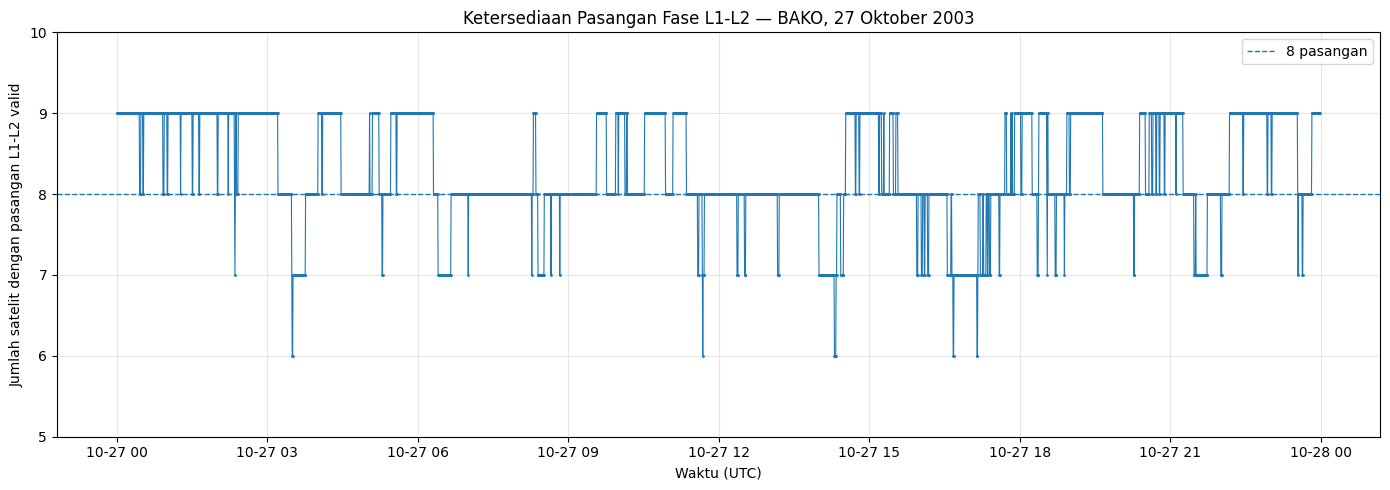

In [20]:

import matplotlib.pyplot as plt
import pandas as pd

# Siapkan data jumlah pasangan per epoch
pair_counts = pairs_per_epoch.to_series()
pair_counts.index = times

# Buat grafik
plt.figure(figsize=(14, 5))
plt.plot(
    pair_counts.index,
    pair_counts.values,
    linewidth=0.8,
    marker=".",
    markersize=2
)

plt.axhline(
    y=8,
    linestyle="--",
    linewidth=1,
    label="8 pasangan"
)

plt.xlabel("Waktu (UTC)")
plt.ylabel("Jumlah satelit dengan pasangan L1-L2 valid")
plt.title("Ketersediaan Pasangan Fase L1-L2 — BAKO, 27 Oktober 2003")
plt.yticks(range(0, 11))
plt.ylim(5, 10)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [21]:

# Ketersediaan observasi fase dan kode
L1L2_valid = obs["L1"].notnull() & obs["L2"].notnull()
C1P2_valid = obs["C1"].notnull() & obs["P2"].notnull()

# Kombinasi empat observasi tersedia pada satelit dan epoch yang sama
all_four_valid = L1L2_valid & C1P2_valid

print("AUDIT KOMBINASI FASE DAN KODE")
print("Pasangan L1-L2 valid :", int(L1L2_valid.sum().item()))
print("Pasangan C1-P2 valid :", int(C1P2_valid.sum().item()))
print("L1-L2 dan C1-P2 valid:", int(all_four_valid.sum().item()))

print(
    "Persentase kombinasi empat observasi dari pasangan L1-L2 (%):",
    round(
        int(all_four_valid.sum().item())
        / int(L1L2_valid.sum().item()) * 100,
        2
    )
)


AUDIT KOMBINASI FASE DAN KODE
Pasangan L1-L2 valid : 23880
Pasangan C1-P2 valid : 23880
L1-L2 dan C1-P2 valid: 23880
Persentase kombinasi empat observasi dari pasangan L1-L2 (%): 100.0


In [22]:

# Statistik nilai valid untuk observasi utama
variables = ["L1", "L2", "C1", "P2"]

print("STATISTIK OBSERVASI GNSS BAKO DOY 300")

for var in variables:
    values = obs[var].to_numpy().ravel()
    values = values[pd.notna(values)]

    print(f"\n{var}")
    print("Jumlah valid :", len(values))
    print("Minimum      :", values.min())
    print("Persentil 1% :", round(float(pd.Series(values).quantile(0.01)), 3))
    print("Median       :", round(float(pd.Series(values).median()), 3))
    print("Persentil 99%:", round(float(pd.Series(values).quantile(0.99)), 3))
    print("Maksimum     :", values.max())


STATISTIK OBSERVASI GNSS BAKO DOY 300

L1
Jumlah valid : 24237
Minimum      : -6493951.415
Persentil 1% : -4874801.057
Median       : 10777578.032
Persentil 99%: 72701970.881
Maksimum     : 80635604.746

L2
Jumlah valid : 23880
Minimum      : -5002565.758
Persentil 1% : -3756899.686
Median       : 4192727.092
Persentil 99%: 39974382.331
Maksimum     : 51678526.202

C1
Jumlah valid : 24254
Minimum      : 20659955.148
Persentil 1% : 22194784.158
Median       : 41836847.06
Persentil 99%: 60700421.2
Maksimum     : 63077138.455

P2
Jumlah valid : 23880
Minimum      : 20659955.77
Persentil 1% : 22186788.712
Median       : 41681934.587
Persentil 99%: 60608296.601
Maksimum     : 63070201.623


In [23]:

# Perubahan fase antara dua epoch berurutan
phase_diff = obs[["L1", "L2"]].diff(dim="time")

print("STATISTIK PERUBAHAN FASE ANTAREPOCH")

for var in ["L1", "L2"]:
    values = phase_diff[var].to_numpy().ravel()
    values = values[pd.notna(values)]

    abs_values = abs(values)

    print(f"\n{var}")
    print("Jumlah perubahan valid :", len(values))
    print("Median |perubahan|     :", round(float(pd.Series(abs_values).median()), 4))
    print("Persentil 95%          :", round(float(pd.Series(abs_values).quantile(0.95)), 4))
    print("Persentil 99%          :", round(float(pd.Series(abs_values).quantile(0.99)), 4))
    print("Maksimum |perubahan|   :", round(float(abs_values.max()), 4))


STATISTIK PERUBAHAN FASE ANTAREPOCH

L1
Jumlah perubahan valid : 24159
Median |perubahan|     : 69404.729
Persentil 95%          : 158508.1336
Persentil 99%          : 170761.1695
Maksimum |perubahan|   : 45820821.228

L2
Jumlah perubahan valid : 23772
Median |perubahan|     : 54019.0855
Persentil 95%          : 123465.9198
Persentil 99%          : 133034.1185
Maksimum |perubahan|   : 141578.548


In [25]:

# Identifikasi 10 perubahan fase absolut terbesar
print("10 PERUBAHAN FASE TERBESAR")

for var in ["L1", "L2"]:
    df_diff = (
        phase_diff[var]
        .to_dataframe(name="delta_phase")
        .dropna()
    )

    df_diff["abs_delta"] = df_diff["delta_phase"].abs()
    top10 = df_diff.nlargest(10, "abs_delta").reset_index()

    print(f"\n=== {var} ===")
    print(
        top10[["time", "sv", "delta_phase", "abs_delta"]]
        .to_string(index=False)
    )


10 PERUBAHAN FASE TERBESAR

=== L1 ===


KeyError: "['sv'] not in index"

In [26]:

print("10 PERUBAHAN FASE TERBESAR")

for var in ["L1", "L2"]:
    df_diff = phase_diff[var].to_dataframe(name="delta_phase").dropna()

    df_diff["abs_delta"] = df_diff["delta_phase"].abs()
    top10 = df_diff.nlargest(10, "abs_delta").reset_index()

    # Periksa nama kolom indeks yang tersedia
    print(f"\n=== {var} ===")
    print("Kolom tersedia:", top10.columns.tolist())

    # Tampilkan tabel tanpa mengasumsikan nama kolom indeks
    print(top10.to_string(index=False))


10 PERUBAHAN FASE TERBESAR

=== L1 ===
Kolom tersedia: ['time', 'Satelit', 'delta_phase', 'abs_delta']
                   time Satelit   delta_phase    abs_delta
2003-10-27 11:23:30.060     G01 -4.582082e+07 45820821.228
2003-10-27 01:24:30.007     G14 -2.419496e+06  2419496.068
2003-10-27 23:38:00.126     G17  1.827771e+05   182777.147
2003-10-27 23:37:30.126     G17  1.826793e+05   182679.340
2003-10-27 23:37:00.126     G17  1.825780e+05   182577.985
2003-10-27 23:36:30.126     G17  1.824788e+05   182478.788
2003-10-27 23:36:00.126     G17  1.823754e+05   182375.405
2003-10-27 23:35:30.126     G17  1.822672e+05   182267.194
2003-10-27 23:35:00.126     G17  1.821592e+05   182159.152
2003-10-27 23:34:30.126     G17  1.820456e+05   182045.579

=== L2 ===
Kolom tersedia: ['time', 'Satelit', 'delta_phase', 'abs_delta']
                   time Satelit  delta_phase  abs_delta
2003-10-27 23:33:00.126     G17   141578.548 141578.548
2003-10-27 23:32:30.126     G17   141480.353 141480.353
2003

In [27]:

# RINGKASAN AUDIT AWAL RINEX BAKO DOY 300

n_epoch = obs.sizes["time"]
n_sat = obs.sizes["Satelit"] if "Satelit" in obs.sizes else obs.sizes["sv"]

waktu_awal = pd.Timestamp(obs.time.values[0])
waktu_akhir = pd.Timestamp(obs.time.values[-1])

print("RINGKASAN AUDIT AWAL RINEX")
print("=" * 50)
print("Stasiun             : BAKO")
print("Tanggal             : 27 Oktober 2003 (DOY 300)")
print("File                : bako3000.03o")
print("Jumlah epoch        :", n_epoch)
print("Jumlah satelit      :", n_sat)
print("Waktu awal           :", waktu_awal)
print("Waktu akhir          :", waktu_akhir)
print("Interval nominal    : 30 detik")
print("Observasi tersedia  : L1, L2, C1, P2, D1")
print("P1                  : seluruh nilai kosong")
print("Pasangan L1-L2      : 23.880")
print("Pasangan L1-L2-C1-P2: 23.880")
print("Kandidat anomali    : L1 G01 dan G14; pola fase G17")
print("Status              : Audit awal selesai")
print("Catatan             : Kandidat anomali belum ditelusuri mendalam")


RINGKASAN AUDIT AWAL RINEX
Stasiun             : BAKO
Tanggal             : 27 Oktober 2003 (DOY 300)
File                : bako3000.03o
Jumlah epoch        : 2878
Jumlah satelit      : 28
Waktu awal           : 2003-10-27 00:00:30
Waktu akhir          : 2003-10-27 23:59:00.128000
Interval nominal    : 30 detik
Observasi tersedia  : L1, L2, C1, P2, D1
P1                  : seluruh nilai kosong
Pasangan L1-L2      : 23.880
Pasangan L1-L2-C1-P2: 23.880
Kandidat anomali    : L1 G01 dan G14; pola fase G17
Status              : Audit awal selesai
Catatan             : Kandidat anomali belum ditelusuri mendalam


In [28]:

from pathlib import Path

folder_halloween = Path(
    r"C:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily\HALLOWEEN STORM 2003"
)

print("Folder Halloween Storm ditemukan:", folder_halloween.exists())

if folder_halloween.exists():
    print("\nDaftar isi folder utama:")
    for item in sorted(folder_halloween.iterdir()):
        jenis = "Folder" if item.is_dir() else "File"
        print(f"{jenis:8} | {item.name}")


Folder Halloween Storm ditemukan: True

Daftar isi folder utama:
Folder   | DOY 300_27 OCT 2003
Folder   | DOY 301_28 OCT 2003
Folder   | DOY 302_29 OCT 2003
Folder   | DOY 303_30 OCT 2003
Folder   | DOY 304_31 OCT 2003
Folder   | DOY 305_01 NOV 2003
Folder   | DOY 306_02 NOV 2003
Folder   | DOY 307_03 NOV 2003


In [29]:

from pathlib import Path
import pandas as pd

folder_halloween = Path(
    r"C:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily\HALLOWEEN STORM 2003"
)

records = []

for folder_doy in sorted(folder_halloween.iterdir()):
    if not folder_doy.is_dir():
        continue

    for file in folder_doy.rglob("*"):
        if file.is_file():
            records.append({
                "Folder_DOY": folder_doy.name,
                "Subfolder": file.parent.name,
                "Nama_File": file.name,
                "Ekstensi": "".join(file.suffixes),
                "Ukuran_MB": round(file.stat().st_size / (1024**2), 3),
                "Path": str(file)
            })

inventaris = pd.DataFrame(records)

print("Jumlah file ditemukan:", len(inventaris))
print("Jumlah folder tanggal:", inventaris["Folder_DOY"].nunique())

display(
    inventaris[
        ["Folder_DOY", "Subfolder", "Nama_File", "Ekstensi", "Ukuran_MB"]
    ].sort_values(["Folder_DOY", "Subfolder", "Nama_File"])
)


Jumlah file ditemukan: 27
Jumlah folder tanggal: 8


,Folder_DOY,Subfolder,Nama_File,Ekstensi,Ukuran_MB
2,DOY 300_27 OCT 2003,BAKO,bako.ipynb,.ipynb,0.144
3,DOY 300_27 OCT 2003,BAKO,bako.py,.py,0.000
4,DOY 300_27 OCT 2003,BAKO,bako3000.03o,.03o,2.006
5,DOY 300_27 OCT 2003,BAKO,bako3000.03o.Z,.03o.Z,0.770
0,DOY 300_27 OCT 2003,DOY 300_27 OCT 2003,ntus3000.03o.Z,.03o.Z,0.958
1,DOY 300_27 OCT 2003,DOY 300_27 OCT 2003,pimo3000.03o.Z,.03o.Z,0.805
6,DOY 301_28 OCT 2003,DOY 301_28 OCT 2003,bako3010.03o.Z,.03o.Z,0.769
7,DOY 301_28 OCT 2003,DOY 301_28 OCT 2003,ntus3010.03o.Z,.03o.Z,1.075
8,DOY 301_28 OCT 2003,DOY 301_28 OCT 2003,pimo3010.03o.Z,.03o.Z,0.820
9,DOY 302_29 OCT 2003,DOY 302_29 OCT 2003,bako3020.03o.Z,.03o.Z,0.769


In [30]:

from pathlib import Path
import gzip
import shutil

file_z = (
    Path(r"C:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily")
    / "HALLOWEEN STORM 2003"
    / "DOY 301_28 OCT 2003"
    / "bako3010.03o.Z"
)

print("File ditemukan:", file_z.exists())

if file_z.exists():
    print("Ukuran file:", round(file_z.stat().st_size / (1024**2), 3), "MB")

    try:
        with gzip.open(file_z, "rb") as f:
            header = f.read(80)

        print("Dapat dibaca dengan gzip: Ya")
        print("Contoh byte hasil dekompresi:", header)

    except Exception as e:
        print("Dapat dibaca dengan gzip: Tidak")
        print("Jenis kendala:", type(e).__name__)
        print("Pesan:", str(e))


File ditemukan: True
Ukuran file: 0.769 MB
Dapat dibaca dengan gzip: Tidak
Jenis kendala: BadGzipFile
Pesan: Not a gzipped file (b'\x1f\x9d')


In [32]:
from pathlib import Path

folder_halloween = Path(
    r"C:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily\HALLOWEEN STORM 2003"
)

for folder_doy in sorted(folder_halloween.iterdir()):
    if not folder_doy.is_dir():
        continue

    print(f"\n{folder_doy.name}")

    for file in sorted(folder_doy.rglob("*")):
        if file.is_file() and file.suffix.lower() in [".03o", ".z"]:
            print(f"  {file.name} | {file.stat().st_size / (1024**2):.3f} MB")


DOY 300_27 OCT 2003
  bako3000.03o | 2.006 MB
  bako3000.03o.Z | 0.770 MB
  ntus3000.03o.Z | 0.958 MB
  pimo3000.03o.Z | 0.805 MB

DOY 301_28 OCT 2003
  bako3010.03o | 2.007 MB
  bako3010.03o.Z | 0.769 MB
  ntus3010.03o.Z | 1.075 MB
  pimo3010.03o.Z | 0.820 MB

DOY 302_29 OCT 2003
  bako3020.03o | 2.008 MB
  bako3020.03o.Z | 0.769 MB
  ntus3020.03o.Z | 1.076 MB
  pimo3020.03o.Z | 0.818 MB

DOY 303_30 OCT 2003
  bako3030.03o | 2.007 MB
  bako3030.03o.Z | 0.768 MB
  ntus3030.03o.Z | 1.075 MB
  pimo3030.03o.Z | 0.815 MB

DOY 304_31 OCT 2003
  bako3040.03o | 1.999 MB
  bako3040.03o.Z | 0.764 MB
  ntus3040.03o.Z | 1.080 MB
  pimo3040.03o.Z | 0.810 MB

DOY 305_01 NOV 2003
  bako3050.03o | 2.008 MB
  bako3050.03o.Z | 0.769 MB
  ntus3050.03o.Z | 1.083 MB
  pimo3050.03o.Z | 0.814 MB

DOY 306_02 NOV 2003
  bako3060.03o | 2.007 MB
  bako3060.03o.Z | 0.768 MB
  ntus3060.03o.Z | 1.081 MB
  pimo3060.03o.Z | 0.820 MB

DOY 307_03 NOV 2003
  bako3070.03o | 2.008 MB
  bako3070.03o.Z | 0.767 MB
  ntus30

In [33]:
from pathlib import Path
import georinex as gr

file_rinex = (
    Path(r"C:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily")
    / "HALLOWEEN STORM 2003"
    / "DOY 301_28 OCT 2003"
    / "bako3010.03o"
)

print("File ditemukan:", file_rinex.exists())

if file_rinex.exists():
    print("Ukuran file:", round(file_rinex.stat().st_size / (1024**2), 3), "MB")

    try:
        obs = gr.load(str(file_rinex))

        print("\nFile berhasil dibaca oleh GeoRinex.")
        print("Dimensi data:", obs.sizes)
        print("Variabel observasi:", list(obs.data_vars))
        print("Waktu awal:", obs.time.values[0])
        print("Waktu akhir:", obs.time.values[-1])

    except Exception as e:
        print("\nFile gagal dibaca.")
        print("Jenis kendala:", type(e).__name__)
        print("Pesan:", str(e))

File ditemukan: True
Ukuran file: 2.007 MB

File berhasil dibaca oleh GeoRinex.
Dimensi data: Frozen({'time': 2878, 'sv': 28})
Variabel observasi: ['L1', 'L2', 'C1', 'P2', 'P1', 'D1']
Waktu awal: 2003-10-28T00:00:30.000000000
Waktu akhir: 2003-10-28T23:59:00.127000000


c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))
c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'sv' ('sv',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))


In [34]:

from pathlib import Path
import pandas as pd
import georinex as gr

folder_halloween = (
    Path(r"C:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily")
    / "HALLOWEEN STORM 2003"
)

hasil_audit = []

for doy in range(300, 308):
    folder_doy = next(
        p for p in folder_halloween.iterdir()
        if p.is_dir() and p.name.startswith(f"DOY {doy}_")
    )

    file_rinex = folder_doy / f"bako{doy}0.03o"

    print(f"Memeriksa DOY {doy}: {file_rinex.name}")

    if not file_rinex.exists():
        hasil_audit.append({
            "DOY": doy,
            "File": file_rinex.name,
            "Status": "FILE TIDAK DITEMUKAN"
        })
        continue

    try:
        obs = gr.load(str(file_rinex))

        waktu = pd.DatetimeIndex(pd.to_datetime(obs.time.values))
        selisih = waktu.to_series().diff().dt.total_seconds().dropna()

        hasil_audit.append({
            "DOY": doy,
            "Tanggal": waktu[0].strftime("%Y-%m-%d"),
            "File": file_rinex.name,
            "Ukuran_MB": round(file_rinex.stat().st_size / (1024**2), 3),
            "Epoch": obs.sizes["time"],
            "Satelit": obs.sizes["sv"],
            "Waktu_awal_UTC": waktu[0].strftime("%H:%M:%S"),
            "Waktu_akhir_UTC": waktu[-1].strftime("%H:%M:%S"),
            "Interval_median_detik": round(selisih.median(), 3),
            "Gap_di_atas_30_5_detik": int((selisih > 30.5).sum()),
            "Status": "BERHASIL DIBACA"
        })

    except Exception as e:
        hasil_audit.append({
            "DOY": doy,
            "File": file_rinex.name,
            "Status": f"GAGAL: {type(e).__name__}: {e}"
        })

audit_bako = pd.DataFrame(hasil_audit)

display(audit_bako)


Memeriksa DOY 300: bako3000.03o
Memeriksa DOY 301: bako3010.03o


c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))
c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'sv' ('sv',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))


Memeriksa DOY 302: bako3020.03o


c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))
c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'sv' ('sv',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))


Memeriksa DOY 303: bako3030.03o


c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))
c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'sv' ('sv',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))


... (5 outputs left out)

c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))
c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'sv' ('sv',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))


Memeriksa DOY 307: bako3070.03o


c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))
c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'sv' ('sv',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))


,DOY,File,Status,Tanggal,Ukuran_MB,Epoch,Satelit,Waktu_awal_UTC,Waktu_akhir_UTC,Interval_median_detik,Gap_di_atas_30_5_detik
0,300,bako3000.03o,FILE TIDAK DITEMUKAN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,301,bako3010.03o,BERHASIL DIBACA,2003-10-28,2.007,2878.0,28.0,00:00:30,23:59:00,30.0,0.0
2,302,bako3020.03o,BERHASIL DIBACA,2003-10-29,2.008,2878.0,28.0,00:00:30,23:59:00,30.0,0.0
3,303,bako3030.03o,BERHASIL DIBACA,2003-10-30,2.007,2878.0,28.0,00:00:30,23:59:00,30.0,0.0
4,304,bako3040.03o,BERHASIL DIBACA,2003-10-31,1.999,2867.0,28.0,00:06:00,23:59:00,30.0,0.0
5,305,bako3050.03o,BERHASIL DIBACA,2003-11-08,2.008,2878.0,28.0,00:00:30,23:59:00,30.0,0.0
6,306,bako3060.03o,BERHASIL DIBACA,2003-11-02,2.007,2878.0,28.0,00:00:30,23:59:00,30.0,0.0
7,307,bako3070.03o,BERHASIL DIBACA,2003-11-03,2.008,2878.0,28.0,00:00:30,23:59:00,30.0,0.0


In [35]:

from pathlib import Path
import georinex as gr

folder_halloween = (
    Path(r"C:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily")
    / "HALLOWEEN STORM 2003"
)

# Periksa lokasi file BAKO DOY 300 dan DOY 305
for doy in [300, 305]:
    nama_file = f"bako{doy}0.03o"

    kandidat = [
        p for p in folder_halloween.rglob(nama_file)
        if p.is_file()
    ]

    print(f"\n{'=' * 55}")
    print(f"DOY {doy}: {nama_file}")
    print("Jumlah file ditemukan:", len(kandidat))

    for file_rinex in kandidat:
        print("Path:", file_rinex)

        try:
            obs = gr.load(str(file_rinex))

            print("Waktu awal:", obs.time.values[0])
            print("Waktu akhir:", obs.time.values[-1])
            print("Jumlah epoch:", obs.sizes["time"])

        except Exception as e:
            print("Gagal dibaca:", type(e).__name__, str(e))

    # Baca informasi header RINEX untuk DOY 305
    if doy == 305 and kandidat:
        print("\nBaris header penting DOY 305:")

        with kandidat[0].open(
            "r", encoding="ascii", errors="replace"
        ) as f:
            for line in f:
                if "END OF HEADER" in line:
                    break

                if any(
                    kata in line
                    for kata in [
                        "RINEX VERSION",
                        "MARKER NAME",
                        "TIME OF FIRST OBS",
                        "TIME OF LAST OBS",
                        "INTERVAL"
                    ]
                ):
                    print(line.rstrip())



DOY 300: bako3000.03o
Jumlah file ditemukan: 1
Path: C:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily\HALLOWEEN STORM 2003\DOY 300_27 OCT 2003\BAKO\bako3000.03o


c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))
c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'sv' ('sv',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))


Waktu awal: 2003-10-27T00:00:30.000000000
Waktu akhir: 2003-10-27T23:59:00.128000000
Jumlah epoch: 2878

DOY 305: bako3050.03o
Jumlah file ditemukan: 1
Path: C:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily\HALLOWEEN STORM 2003\DOY 305_01 NOV 2003\bako3050.03o
Waktu awal: 2003-11-08T00:00:30.000000000
Waktu akhir: 2003-11-08T23:59:00.127000000
Jumlah epoch: 2878

Baris header penting DOY 305:
     2.10           OBSERVATION DATA    G (GPS)             RINEX VERSION / TYPE
bako                                                        MARKER NAME
  2003    11     8     0     0   30.0000000     GPS         TIME OF FIRST OBS


c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))
c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'sv' ('sv',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))


In [37]:

from pathlib import Path
import pandas as pd

folder_halloween = (
    Path(r"C:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily")
    / "HALLOWEEN STORM 2003"
)

hasil_header = []

for doy in range(300, 308):
    nama_file = f"bako{doy}0.03o"
    kandidat = [
        p for p in folder_halloween.rglob(nama_file)
        if p.is_file()
    ]

    tanggal_harapan = pd.Timestamp("2003-01-01") + pd.Timedelta(days=doy - 1)

    if not kandidat:
        hasil_header.append({
            "DOY": doy,
            "Tanggal_seharusnya": tanggal_harapan.strftime("%Y-%m-%d"),
            "File": nama_file,
            "Tanggal_header": None,
            "Kesesuaian": "FILE TIDAK DITEMUKAN"
        })
        continue

    file_rinex = kandidat[0]
    tanggal_header = None
    waktu_header = None

    with file_rinex.open("r", encoding="ascii", errors="replace") as f:
        for line in f:
            if "TIME OF FIRST OBS" in line:
                bagian = line[:43].split()

                try:
                    tahun, bulan, hari = map(int, bagian[:3])
                    jam, menit = map(int, bagian[3:5])
                    detik = float(bagian[5])

                    tanggal_header = pd.Timestamp(
                        year=tahun,
                        month=bulan,
                        day=hari
                    )
                    waktu_header = (
                        f"{jam:02d}:{menit:02d}:{detik:07.4f}"
                    )
                except (ValueError, IndexError):
                    pass

                break

            if "END OF HEADER" in line:
                break

    cocok = (
        tanggal_header is not None
        and tanggal_header.normalize() == tanggal_harapan.normalize()
    )

    hasil_header.append({
        "DOY": doy,
        "Tanggal_seharusnya": tanggal_harapan.strftime("%Y-%m-%d"),
        "File": nama_file,
        "Tanggal_header": (
            tanggal_header.strftime("%Y-%m-%d")
            if tanggal_header is not None else None
        ),
        "Waktu_awal_header": waktu_header,
        "Kesesuaian": "SESUAI" if cocok else "PERLU DIVERIFIKASI"
    })

audit_header_bako = pd.DataFrame(hasil_header)
display(audit_header_bako)


,DOY,Tanggal_seharusnya,File,Tanggal_header,Waktu_awal_header,Kesesuaian
0,300,2003-10-27,bako3000.03o,2003-10-27,00:00:30.0000,SESUAI
1,301,2003-10-28,bako3010.03o,2003-10-28,00:00:30.0000,SESUAI
2,302,2003-10-29,bako3020.03o,2003-10-29,00:00:30.0000,SESUAI
3,303,2003-10-30,bako3030.03o,2003-10-30,00:00:30.0000,SESUAI
4,304,2003-10-31,bako3040.03o,2003-10-31,00:06:00.0000,SESUAI
5,305,2003-11-01,bako3050.03o,2003-11-08,00:00:30.0000,PERLU DIVERIFIKASI
6,306,2003-11-02,bako3060.03o,2003-11-02,00:00:30.0000,SESUAI
7,307,2003-11-03,bako3070.03o,2003-11-03,00:00:30.0000,SESUAI


In [38]:

from pathlib import Path
import pandas as pd

folder_halloween = (
    Path(r"C:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily")
    / "HALLOWEEN STORM 2003"
)

hasil_header = []

for doy in range(300, 308):
    nama_file = f"bako{doy}0.03o"
    kandidat = [
        p for p in folder_halloween.rglob(nama_file)
        if p.is_file()
    ]

    tanggal_harapan = pd.Timestamp("2003-01-01") + pd.Timedelta(days=doy - 1)

    if not kandidat:
        hasil_header.append({
            "DOY": doy,
            "Tanggal_seharusnya": tanggal_harapan.strftime("%Y-%m-%d"),
            "File": nama_file,
            "Tanggal_header": None,
            "Kesesuaian": "FILE TIDAK DITEMUKAN"
        })
        continue

    file_rinex = kandidat[0]
    tanggal_header = None
    waktu_header = None

    with file_rinex.open("r", encoding="ascii", errors="replace") as f:
        for line in f:
            if "TIME OF FIRST OBS" in line:
                bagian = line[:43].split()

                try:
                    tahun, bulan, hari = map(int, bagian[:3])
                    jam, menit = map(int, bagian[3:5])
                    detik = float(bagian[5])

                    tanggal_header = pd.Timestamp(
                        year=tahun,
                        month=bulan,
                        day=hari
                    )
                    waktu_header = (
                        f"{jam:02d}:{menit:02d}:{detik:07.4f}"
                    )
                except (ValueError, IndexError):
                    pass

                break

            if "END OF HEADER" in line:
                break

    cocok = (
        tanggal_header is not None
        and tanggal_header.normalize() == tanggal_harapan.normalize()
    )

    hasil_header.append({
        "DOY": doy,
        "Tanggal_seharusnya": tanggal_harapan.strftime("%Y-%m-%d"),
        "File": nama_file,
        "Tanggal_header": (
            tanggal_header.strftime("%Y-%m-%d")
            if tanggal_header is not None else None
        ),
        "Waktu_awal_header": waktu_header,
        "Kesesuaian": "SESUAI" if cocok else "PERLU DIVERIFIKASI"
    })

audit_header_bako = pd.DataFrame(hasil_header)
display(audit_header_bako)


,DOY,Tanggal_seharusnya,File,Tanggal_header,Waktu_awal_header,Kesesuaian
0,300,2003-10-27,bako3000.03o,2003-10-27,00:00:30.0000,SESUAI
1,301,2003-10-28,bako3010.03o,2003-10-28,00:00:30.0000,SESUAI
2,302,2003-10-29,bako3020.03o,2003-10-29,00:00:30.0000,SESUAI
3,303,2003-10-30,bako3030.03o,2003-10-30,00:00:30.0000,SESUAI
4,304,2003-10-31,bako3040.03o,2003-10-31,00:06:00.0000,SESUAI
5,305,2003-11-01,bako3050.03o,2003-11-08,00:00:30.0000,PERLU DIVERIFIKASI
6,306,2003-11-02,bako3060.03o,2003-11-02,00:00:30.0000,SESUAI
7,307,2003-11-03,bako3070.03o,2003-11-03,00:00:30.0000,SESUAI
